# Position held: individuals with a dated position, per century

In [1]:
import json
import re
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position counts only with both a start time (P580) and an end time (P582); a position without them, or with a point in time (P585) only, does not count. Individuals are placed in their century of birth (`individual_enriched`, Wikidata or estimated).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision
str,str,i64,i64,i64,i64
"""Q65593540""","""Q65482993""",2014,11,2020,11
"""Q21001584""","""Q18171345""",2009,11,2011,11
"""Q98247472""","""Q65477748""",2020,11,2026,11
"""Q6214979""","""Q81531912""",1873,9,1875,9
"""Q65585278""","""Q65192029""",2014,11,2020,11


In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
births = con.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth_year
    FROM   individual_enriched
    WHERE  birth_date.year IS NOT NULL
''').pl()
con.close()
born_per_century = births.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('individuals born'))
print(f'{births.height:,} individuals with a birth year')

7,641,351 individuals with a birth year


## Preprocessing
### Individuals with a dated position, per century of birth

In [4]:
with_dated_position = pl.DataFrame({'qid': dated['qid'].unique()}).join(births, on='qid', how='left')
print(f"{with_dated_position['birth_year'].null_count():,} of {with_dated_position.height:,} individuals with a dated position have no birth year and are left out")

per_century = (
    with_dated_position.drop_nulls('birth_year')
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('with a dated position'))
    .join(born_per_century, on='century', how='right')
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .with_columns(pl.col('with a dated position').fill_null(0))
    .with_columns((100 * pl.col('with a dated position') / pl.col('individuals born')).round(2).alias('% of individuals born'))
    .select('century', 'individuals born', 'with a dated position', '% of individuals born')
    .sort('century')
)
assert per_century['century'].is_unique().all()
per_century

53,878 of 454,417 individuals with a dated position have no birth year and are left out


century,individuals born,with a dated position,% of individuals born
i64,u32,u32,f64
-500,443,72,16.25
-400,596,104,17.45
-300,702,236,33.62
-200,701,234,33.38
-100,949,166,17.49
0,928,142,15.3
100,1316,96,7.29
200,1718,138,8.03
300,1810,226,12.49


## Figures
### Figure 1: Individuals with a dated position held, per century of birth

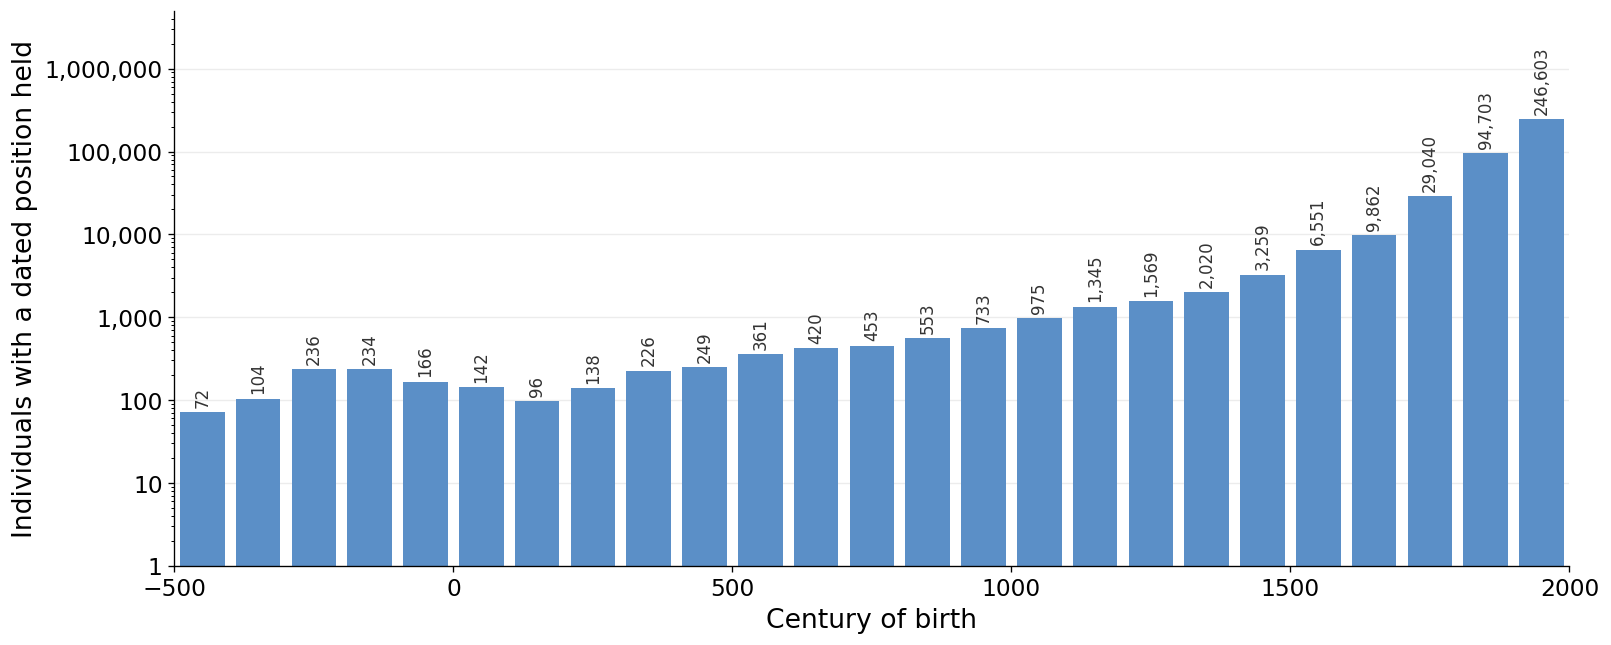

In [5]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['with a dated position'], width=CENTURY * 0.8, color=MAIN_COLOR)
for century, n in per_century.select('century', 'with a dated position').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, per_century['with a dated position'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with a dated position held')
ax.grid(axis='y')
plt.show()

### Figure 2: Share of the individuals born in each century with a dated position held

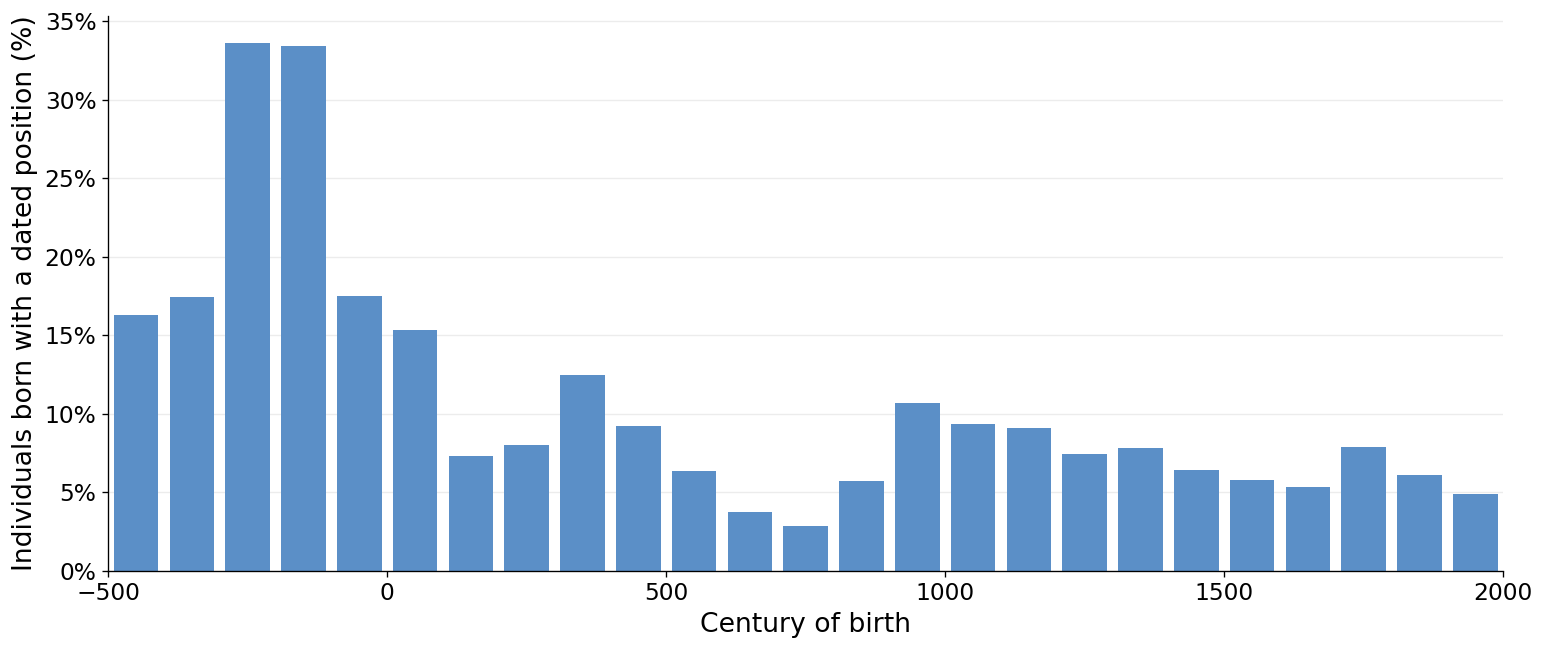

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['% of individuals born'], width=CENTURY * 0.8, color=MAIN_COLOR)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals born with a dated position (%)')
ax.grid(axis='y')
plt.show()